# P1 — Industrial IoT Telemetry Anomaly Detection & Failure Prediction
**Deliverables:** RUL regression (MAE/RMSE), failure classifier, threshold/recall report. Synthetic starter data.

In [12]:
!pip -q install scikit-learn matplotlib pandas

In [13]:
from pathlib import Path
import os
DATA_DIR = Path("/kaggle/input/datasets/babblu123/real-world-ml-genai-kaggle-complete/real_world_ml_genai_lab/datasets")
if not DATA_DIR.exists():
    DATA_DIR = Path("../datasets")
if not DATA_DIR.exists():
    DATA_DIR = Path("datasets")
print("Dataset directory:", DATA_DIR.resolve())

import pandas as pd, numpy as np, matplotlib.pyplot as plt
df = pd.read_csv(DATA_DIR/"p1_iot_telemetry.csv")
df.head()

Dataset directory: /kaggle/input/datasets/babblu123/real-world-ml-genai-kaggle-complete/real_world_ml_genai_lab/datasets


,timestamp,machine_id,vibration,spindle_temperature,motor_voltage,acoustic_noise,wear_index,rul_hours,failure_within_24h
0,2025-01-01 00:00:00,CNC-002,4.663692,72.437737,216.904575,61.552792,100.000000,188.181433,0
1,2025-01-01 01:00:00,CNC-011,4.298696,61.680127,216.406169,39.794613,100.000000,204.890942,0
2,2025-01-01 02:00:00,CNC-016,5.210402,76.003610,211.640081,51.116451,92.558647,194.735484,0
3,2025-01-01 03:00:00,CNC-019,4.581344,77.524518,225.141795,54.617696,98.453509,197.509078,1
4,2025-01-01 04:00:00,CNC-020,5.461270,54.391718,222.815754,56.613428,100.000000,157.583127,0


In [14]:
df.info()
display(df.isna().sum())
display(df["failure_within_24h"].value_counts(normalize=True))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   timestamp            2500 non-null   object 
 1   machine_id           2500 non-null   object 
 2   vibration            2500 non-null   float64
 3   spindle_temperature  2500 non-null   float64
 4   motor_voltage        2500 non-null   float64
 5   acoustic_noise       2500 non-null   float64
 6   wear_index           2500 non-null   float64
 7   rul_hours            2500 non-null   float64
 8   failure_within_24h   2500 non-null   int64  
dtypes: float64(6), int64(1), object(2)
memory usage: 175.9+ KB


timestamp              0
machine_id             0
vibration              0
spindle_temperature    0
motor_voltage          0
acoustic_noise         0
wear_index             0
rul_hours              0
failure_within_24h     0
dtype: int64

failure_within_24h
0    0.8516
1    0.1484
Name: proportion, dtype: float64

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, classification_report, precision_recall_curve
features=["vibration","spindle_temperature","motor_voltage","acoustic_noise","wear_index"]
X=df[features]
Xtr,Xte,ytr,yte=train_test_split(X,df.rul_hours,test_size=.2,random_state=42)
reg=Pipeline([("impute",SimpleImputer()),("poly",PolynomialFeatures(degree=2,include_bias=False)),("scale",StandardScaler()),("model",LinearRegression())])
reg.fit(Xtr,ytr); pred=reg.predict(Xte)
print("RUL MAE:",mean_absolute_error(yte,pred),"RMSE:",mean_squared_error(yte,pred)**.5)

RUL MAE: 11.8966158305414 RMSE: 14.656306787452527


In [16]:
Xtr,Xte,ytr,yte=train_test_split(X,df.failure_within_24h,test_size=.2,random_state=42,stratify=df.failure_within_24h)
clf=Pipeline([("impute",SimpleImputer()),("scale",StandardScaler()),("model",LogisticRegression(class_weight="balanced",max_iter=1000))])
clf.fit(Xtr,ytr); probs=clf.predict_proba(Xte)[:,1]
from sklearn.metrics import roc_auc_score, average_precision_score, confusion_matrix
print("ROC-AUC:",roc_auc_score(yte,probs),"PR-AUC:",average_precision_score(yte,probs))
for threshold in [.2,.3,.4,.5,.6]:
    print("threshold",threshold,classification_report(yte,(probs>=threshold).astype(int),zero_division=0))

ROC-AUC: 0.5484075624920695 PR-AUC: 0.17540607317128748
threshold 0.2               precision    recall  f1-score   support

           0       0.00      0.00      0.00       426
           1       0.15      1.00      0.26        74

    accuracy                           0.15       500
   macro avg       0.07      0.50      0.13       500
weighted avg       0.02      0.15      0.04       500

threshold 0.3               precision    recall  f1-score   support

           0       0.00      0.00      0.00       426
           1       0.15      1.00      0.26        74

    accuracy                           0.15       500
   macro avg       0.07      0.50      0.13       500
weighted avg       0.02      0.15      0.04       500

threshold 0.4               precision    recall  f1-score   support

           0       0.89      0.08      0.14       426
           1       0.15      0.95      0.26        74

    accuracy                           0.20       500
   macro avg       0.52      0

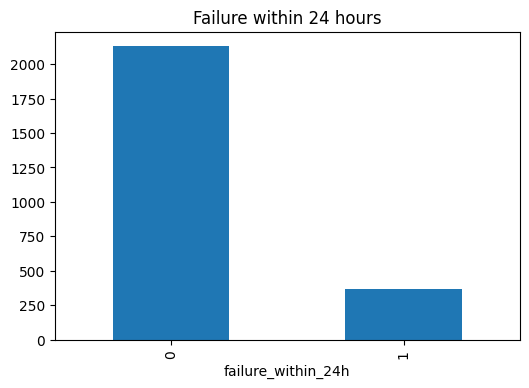

In [17]:
plt.figure(figsize=(6,4)); df.failure_within_24h.value_counts().sort_index().plot(kind="bar"); plt.title("Failure within 24 hours"); plt.show()

## Findings and limitations
Write down MAE/RMSE, ROC-AUC/PR-AUC, chosen threshold and recall. Data is synthetic; this is a workflow demonstration, not a production failure predictor.